In [23]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import umap
sys.path.insert(0, "./cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

### Load Data

In [3]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'stoch_sim*cycdi_0_0.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)

filenames_conds = [filenames[2], filenames[3], filenames[0],
                filenames[1], filenames[4], filenames[5]]

filenames_conds


['C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_erl_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_erl_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_cycdi_0_0.csv']

In [4]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'ODE_sim*cycdi_0_0.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)

filenames_conds_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0],
                filenames_ode[1], filenames_ode[4], filenames_ode[5]]

filenames_conds_ode


['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_cycdi_0_0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_cycdi_0_0.csv']

In [21]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

#reducer save name
r_name = f'reducer_{CURDATE}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [6]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [7]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [8]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [9]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [10]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [11]:
# quick check of protein time course shape
all_prot_tmp.shape

(239958, 720)

In [13]:
# check global max and min vals
[np.amax(all_prot_tmp), np.amin(all_prot_tmp)]

[1.0, 0.0]

In [25]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)


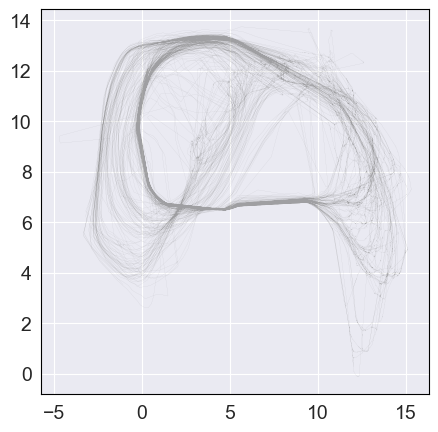

In [26]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot)/len(filenames_conds))
n=1
n1=2
plt.plot(embedding_all[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')



In [24]:
# Save the UMAP object
reducer_filename = Path(SAVE_DIR, r_name)
joblib.dump(reducer, reducer_filename)

['C:\\Users\\olesk\\ECM_mod_output\\reducer_20240502_0.1_0.1_4_0.5.sav']

In [28]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames)
sp = 1
for n in range(len(filenames)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [29]:
all_prot_tmp_ode_ab.shape

(12000, 720)

In [30]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [32]:
# Save all the outputs 
joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_{CURDATE}.sav'))
joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_{CURDATE}.sav'))
joblib.dump(all_prot_tmp, Path(SAVE_DIR, f'all_prot_stoch_conds_{CURDATE}.sav'))


['C:\\Users\\olesk\\ECM_mod_output\\all_prot_stoch_conds_20240502.sav']